In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve

In [3]:
y_train = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\y_train")
x_train = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\x_train")

y_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\y_test")
x_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\x_test")

In [4]:
x_train_arr = x_train.values
x_train_arr

array([[1., 0., 0., ..., 1., 0., 0.],
       [1., 0., 1., ..., 1., 0., 1.],
       [1., 0., 1., ..., 0., 0., 1.],
       ...,
       [0., 1., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 1.],
       [1., 0., 0., ..., 1., 0., 0.]], shape=(5634, 33))

In [5]:
y_train_arr = np.ravel(y_train.values)
y_train_arr.shape

(5634,)

In [7]:
import joblib
xgb_model_tuned = joblib.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\5_2_Model_Training_With_Tuning\Saved_Model\XGB_Tuned")

In [18]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

# Out of Folds Probability based Threshold selection in the training dataset so as to improve classification metrics without data leakage
oof_probs = cross_val_predict(
    xgb_model_tuned,
    x_train_arr,
    y_train_arr,
    cv = cv,
    method = 'predict_proba',
    n_jobs = 1
)[:, 1]



Fitting 5 folds for each of 40 candidates, totalling 200 fits
Fitting 5 folds for each of 40 candidates, totalling 200 fits
Fitting 5 folds for each of 40 candidates, totalling 200 fits
Fitting 5 folds for each of 40 candidates, totalling 200 fits
Fitting 5 folds for each of 40 candidates, totalling 200 fits


In [20]:
oof_probs_churn = oof_probs
print(f"OOF Probabilities Shape : {oof_probs_churn.shape}")

OOF Probabilities Shape : (5634,)


In [22]:
precisions, recalls, thresholds = precision_recall_curve(y_train_arr, oof_probs_churn)

# 2. Compute F1-scores across all candidate thresholds
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)

# 3. Extract the optimal threshold
best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_idx]

print(f"___Threshold Optimization on Training (OOF) Data___")
print(f"Optimal Threshold (Max OOF F1): {optimal_threshold:.4f}")
print(f"OOF Precision at Threshold:     {precisions[best_idx]:.4f}")
print(f"OOF Recall at Threshold:        {recalls[best_idx]:.4f}")
print(f"OOF Best F1-Score:              {f1_scores[best_idx]:.4f}")

___Threshold Optimization on Training (OOF) Data___
Optimal Threshold (Max OOF F1): 0.4541
OOF Precision at Threshold:     0.5822
OOF Recall at Threshold:        0.7104
OOF Best F1-Score:              0.6400


In [24]:
# Now based on the best threshold that I could find on the training dataset, I will apply this threshold to obtain predictions of the model

test_probs_oof = xgb_model_tuned.predict_proba(x_test)[:, 1]
y_pred_thresh_opt = (test_probs_oof >= optimal_threshold).astype(int)

In [27]:
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Classification Report of XGB_Tuned model with threshold : 0.4541
print(classification_report(y_test, y_pred_thresh_opt))

              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1035
           1       0.58      0.72      0.64       374

    accuracy                           0.79      1409
   macro avg       0.73      0.77      0.74      1409
weighted avg       0.81      0.79      0.79      1409



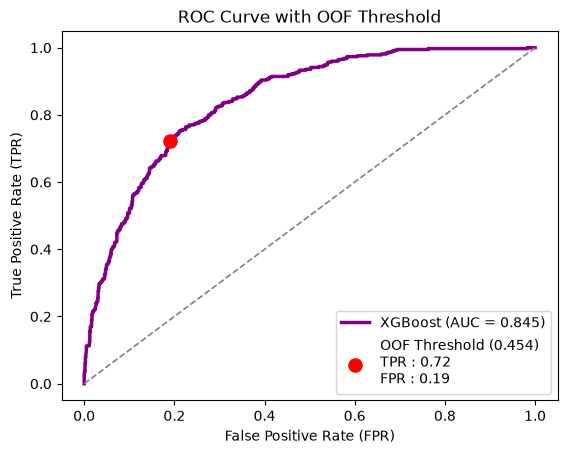

In [26]:
# ROC Curve and AUC
fpr, tpr, roc_thresh = roc_curve(y_test, test_probs_oof)
auc_score = roc_auc_score(y_test, test_probs_oof)

point_idx = np.argmin(np.abs(roc_thresh - optimal_threshold))

plt.plot(fpr, tpr, color = 'purple', lw = 2.5, label = f"XGBoost (AUC = {auc_score :.3f})")
plt.plot([0,1],[0,1], color = 'gray', linestyle = '--', lw = 1.2)
plt.scatter(fpr[point_idx], tpr[point_idx], color = 'red', s = 90, zorder = 5, label = f"OOF Threshold ({optimal_threshold :.3f})\nTPR : {tpr[point_idx] :.2f}\nFPR : {fpr[point_idx] :.2f}")
plt.title("ROC Curve with OOF Threshold")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc = 'lower right')
plt.show()

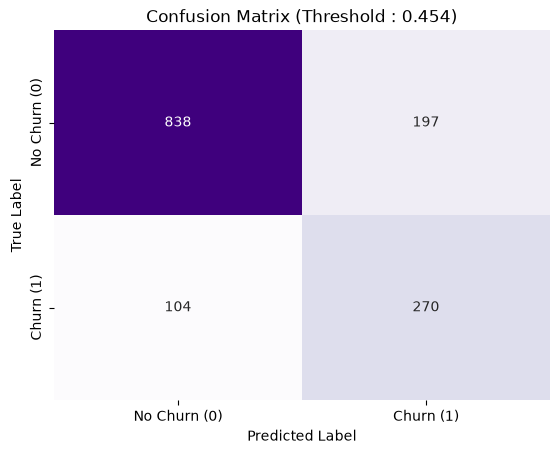

In [28]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred_thresh_opt)
sns.heatmap(cm, annot = True, fmt = 'd', cmap  = "Purples", cbar = False, xticklabels = ["No Churn (0)", "Churn (1)"], yticklabels = ["No Churn (0)", "Churn (1)"])
plt.title(f"Confusion Matrix (Threshold : {optimal_threshold :.3f})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Accuracy : ~79%

Precision (for Churn class): ~58%

Recall (for Churn class) : ~72%

Number of False positives : 197

Number of False negatives : 104

Number of True Positives : 270

Number of True Negatives : 838

After tuning the parameters of the XGB Model, to further improve the classification performance, I decided to get the optimal threshold where the F1 Score on the training dataset is optimal (found to be 0.4541). Using this threshold to differentiate positive and negative class, I stored the new predictions in "y_pred_thresh_opt", based on which I verified the classification performance. 

No data leakage in the test dataset, since threshold optimization was done based on selecting the optimal threshold from the training dataset.

C:\Users\dhanu\AppData\Local\Temp\ipykernel_10908\490779782.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = feature_imp.head(15), x = 'Importance', y = 'Feature', palette = 'mako')


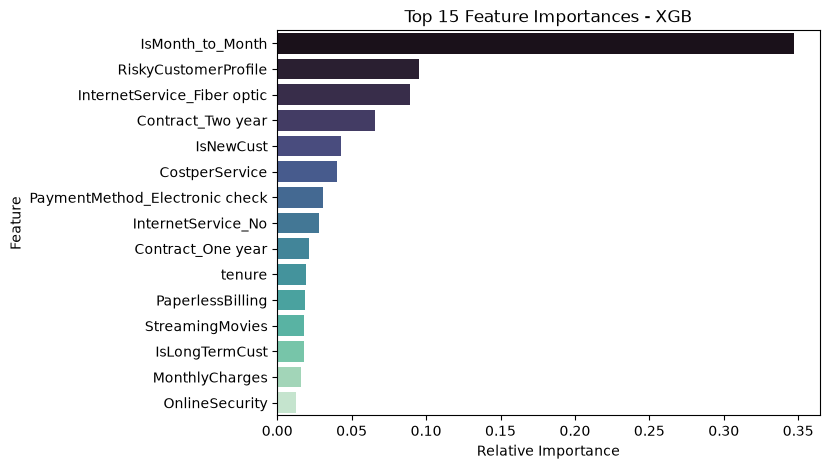

In [10]:
# Feature Importance
import seaborn as sns
import matplotlib.pyplot as plt

best_xgb_model_tuned = xgb_model_tuned.best_estimator_

feature_imp = pd.DataFrame({
    'Feature' : x_test.columns,
    'Importance' : best_xgb_model_tuned.feature_importances_
}).sort_values(by = 'Importance', ascending = False)

plt.figure(figsize = (7,5))
sns.barplot(data = feature_imp.head(15), x = 'Importance', y = 'Feature', palette = 'mako')

plt.title("Top 15 Feature Importances - XGB")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.show()

From the feature importances plot, we can observe that the major dependency whether a customer will churn or not is based on their contract type. If it is monthly, then the customer is most likely to churn. We can retain customers by suggesting to shift towards one or two yearly contract so that they are less likely to churn.

Next important feature is RiskyCustomerProfile, which was engineered during data preparation, which had a major dependency on whether the customer is likely to churn or not.
``` Python
df_cleaned["RiskyCustomerProfile"] = (
        (df_cleaned["IsMonth_to_Month"] == 1) & (df_cleaned["tenure"] <= 12) & (df_cleaned["PaymentMethod_Electronic check"] == 1)
).astype(int)
```
This feature was created based on the satisfaction of the conditions : new customer (tenure less than one year) + contract type (monthly) + payment method (electronic check).
And with this feature, it certainly quantified how likely the customer is to churn or not.